# Laboratorio 4 — Asistente de compras por voz
**Curso de Deep Learning · Maestría 2026**

Asistente que recibe consultas **habladas en español**, las transcribe (ASR), razona con un **LLM local con herramientas** sobre un catálogo indexado con **RAG híbrido** (Amazon ESCI, locale `es`), opera sobre una **tienda simulada** (precios, stock, carrito, cotizaciones y pedidos) y responde **por voz con clonación** a partir de una grabación de referencia.

```
 🎙️ audio usuario
    │  (fin de grabación = t0 de latencia)
    ▼
 ┌──────────────┐   texto    ┌──────────────────────────────────────────────┐
 │ ASR Whisper  │──────────► │ AGENTE (Qwen3-8B 4-bit, tool-calling)         │
 │ large-v3-turbo│ (revisión │  • memoria estructurada (presupuesto, cantidades,│
 └──────────────┘ /corrección)│    preferencias, últimos resultados, cotización)│
                             │  • guardas en código (confirmación, stock,      │
                             │    presupuesto, idempotencia)                   │
                             └───────┬──────────────────────────┬───────────┘
                                     │ herramientas             │ respuesta
              ┌──────────────────────┴───────────┐              ▼
              │ RAG: BM25 propio + e5 denso → RRF │      ┌──────────────┐
              │      → cross-encoder bge-m3       │      │ TTS XTTS-v2  │──► 🔊
              │ TIENDA: SQLite transaccional      │      │ voz clonada  │
              └───────────────────────────────────┘      └──────────────┘
```

**Índice**
0. Configuración del entorno en Colab
1. Preparación de datos (catálogo ≥ 5 000 productos, ≥ 200 consultas, qrels)
2. Índices y recuperación (BM25 base, denso, híbrido, re-ranker)
3. Evaluación de recuperación: modelo base léxico, sistema propuesto y ablación
4. Tienda simulada: generación con semilla y restauración
5. LLM y agente: herramientas, memoria y validaciones
6. 22 escenarios operativos (texto)
7. Voz: grabación de referencia, ASR y TTS con clonación
8. 6 escenarios por voz + repetición con transcripción correcta
9. Calidad de la voz sintetizada (inteligibilidad y semejanza)
10. Latencia por etapa (carga inicial vs consultas)
11. Análisis de aciertos, fallos y limitaciones · Informe automático
12. Demostración en vivo (para el video)

## 0. Configuración del entorno

**Requisitos**: `Entorno de ejecución → Cambiar tipo de entorno → GPU T4` (15 GB VRAM, ~12.7 GB RAM).

**Estructura esperada en Google Drive** (subir la carpeta `solucion/` entregada):
```
MyDrive/master/deeplearning/laboratorio04/solucion/
    Laboratorio4_Asistente_Voz.ipynb   ← este notebook
    lab4/                              ← paquete Python (scripts)
    README.md
```
Los datos, índices, audios y resultados se guardan en `MyDrive/master/deeplearning/laboratorio04/work/` para no repetir la preparación ni perder las grabaciones al reiniciar la sesión.

| Componente | Modelo | Tamaño en GPU | Motivo de la elección |
|---|---|---|---|
| ASR | `openai/whisper-large-v3-turbo` (fp16) | ~1.6 GB | Mejor WER multilingüe abierto; decodificador de 4 capas → ~6× más rápido que large-v3 |
| Embeddings | `intfloat/multilingual-e5-base` (fp16) | ~0.6 GB | Recuperación multilingüe fuerte (MTEB) con coste bajo para 15k fichas |
| Re-ranker | `BAAI/bge-reranker-v2-m3` (fp16) | ~1.1 GB | Cross-encoder multilingüe estado del arte, 568M |
| LLM | `Qwen/Qwen3-8B` NF4 4-bit (modo sin razonamiento) | ~6 GB | Buen español y *tool-calling* nativo; 4 bits para convivir con el resto |
| TTS | `xtts_v2` (Coqui) | ~2 GB | Español + clonación *zero-shot* con 6-30 s de referencia |
| Verificación de hablante | `microsoft/wavlm-base-plus-sv` | ~0.4 GB | x-vectors para medir semejanza de voz |

Todo se ejecuta **localmente en Colab**; solo se descargan pesos y datos (sin APIs de inferencia externas).

In [ ]:
!nvidia-smi --query-gpu=name,memory.total --format=csv
!pip install -q "coqui-tts[codec]>=0.28" six "sentence-transformers>=4.0" "transformers>=4.57" "bitsandbytes>=0.45" accelerate tabulate
!apt-get -qq install -y ffmpeg > /dev/null
# Si pip actualizó torch/transformers ya importados, reinicie la sesión (Entorno de ejecución → Reiniciar) y continúe.
!pip list 2>/dev/null | grep -iE "^(torch|transformers|sentence-transformers|coqui-tts|bitsandbytes) "

name, memory.total [MiB]
Tesla T4, 15360 MiB
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
bitsandbytes                          0.50.2
coqui-tts                             0.28.0
sentence-transformers                 5.7.0
torch                                 2.14.1+cu130
transformers                          5.22.1


In [ ]:
import os, sys, json, time, platform
from pathlib import Path

from google.colab import drive
drive.mount('/content/drive')

SOL_DIR = Path('/content/drive/MyDrive/master/deeplearning/laboratorio04/solucion')   # ← ajustar si se usa otra ruta
WORK_DIR = Path('/content/drive/MyDrive/master/deeplearning/laboratorio04/work')
os.environ['LAB4_BASE'] = str(WORK_DIR)
os.environ['COQUI_TOS_AGREED'] = '1'
os.environ['TOKENIZERS_PARALLELISM'] = 'false'
sys.path.insert(0, str(SOL_DIR))

import importlib, torch, transformers, sentence_transformers, numpy as np, pandas as pd
import lab4
from lab4 import config as C
C.ensure_dirs()

versions = {"python": platform.python_version(), "torch": torch.__version__, "cuda": torch.version.cuda,
            "transformers": transformers.__version__, "sentence_transformers": sentence_transformers.__version__,
            "gpu": torch.cuda.get_device_name(0) if torch.cuda.is_available() else None}
try:
    import TTS; versions["coqui_tts"] = TTS.__version__
except Exception as e:
    versions["coqui_tts"] = f"no importado ({e})"
print(json.dumps(versions, indent=2))
print("Modelos:", C.MODELS)
(C.RESULTS_DIR / "versiones.json").write_text(json.dumps({**versions, "modelos": C.MODELS.__dict__}, indent=2))

Mounted at /content/drive
{
  "python": "3.13.16",
  "torch": "2.14.1+cu130",
  "cuda": "13.0",
  "transformers": "5.22.1",
  "sentence_transformers": "5.7.0",
  "gpu": "Tesla T4",
  "coqui_tts": "0.28.0"
}
Modelos: ModelConfig(asr='openai/whisper-large-v3-turbo', embedder='intfloat/multilingual-e5-base', reranker='BAAI/bge-reranker-v2-m3', llm='Qwen/Qwen3-8B', llm_fallback='Qwen/Qwen2.5-7B-Instruct', llm_4bit=True, tts='tts_models/multilingual/multi-dataset/xtts_v2', speaker_verif='microsoft/wavlm-base-plus-sv', max_new_tokens=384, prefill_chunk_size=1024)


605

## 1. Preparación de datos

* Fuente: Amazon Shopping Queries Dataset (ESCI), **versión reducida** (`small_version == 1`) filtrada por `product_locale == "es"`.
* Los `.parquet` del zip entregado son punteros de Git LFS (≈130 bytes); se descargan los ficheros reales del repositorio oficial (~51 MB ejemplos, ~1.1 GB productos). Los productos se leen **filtrando `es` en la lectura** (filtro de pyarrow) para no saturar la RAM.
* **Consultas**: 150 de `split=train` (**desarrollo**: ajuste de hiperparámetros) y 250 de `split=test` (**evaluación**); separadas por `query_id`. Se exigen ≥ 8 candidatos y ≥ 1 *Exact* por consulta.
* **Catálogo**: todos los productos anotados de esas 400 consultas + distractores reales del locale `es` hasta **15 000 productos**, con título, descripción, *bullet points*, marca, color e id. Se garantiza que haya productos de los tipos usados en los escenarios.
* **Las etiquetas ESCI** se guardan en `qrels.parquet`, separadas del catálogo: el índice y el agente nunca las leen.

In [ ]:
from lab4 import data
data.download_esci()
catalog, queries, qrels = data.prepare_data()
print(catalog.shape, queries.split.value_counts().to_dict(), qrels.esci_label.value_counts().to_dict())
display(queries.head())
display(catalog[["product_id", "title", "brand", "color"]].head())

Descargando shopping_queries_dataset_examples.parquet ...
  51.3 MB
Descargando shopping_queries_dataset_products.parquet ...
  1108.9 MB
Descargando shopping_queries_dataset_sources.csv ...
  1.7 MB
Ejemplos ES (versión reducida): 218,774 pares, 8,049 consultas
Productos añadidos para escenarios: 0
{
  "catalog_products": 15000,
  "annotated_products": 10584,
  "distractors": 4416,
  "dev_queries": 150,
  "test_queries": 250,
  "judgements": 10825,
  "label_distribution": {
    "E": 4517,
    "S": 3716,
    "I": 1862,
    "C": 730
  },
  "seed": 2026
}
(15000, 7) {'test': 250, 'dev': 150} {'E': 4517, 'S': 3716, 'I': 1862, 'C': 730}


,query_id,query,n,n_exact,split
0,228,+telefono motorola solo lamadas sin cable,33,5,dev
1,269,- [ ] kh sin aclarado,40,13,dev
2,902,1 usb macho a dos hembra sin cable,40,11,dev
3,2222,16 cumpleaños decoración sin globos,40,4,dev
4,2615,2 pares pendientes sin agujeros,40,23,dev


,product_id,title,brand,color
0,0078819989,Official SimCity Classic Planning Commission H...,,
1,0199536015,Heart of Darkness and Other Tales (Oxford Worl...,"Oxford University Press España, S.A.",
2,019960925X,One Century of Karl Jaspers' General Psychopat...,OUP Oxford,
3,0201377845,Astan Hogar Confort Sillón Relax con Reclinaci...,Astan Hogar,Chocolate
4,0231081677,"Sima, Q: Records of the Grand Historian - Han ...",Columbia University Press,


In [ ]:
# Comprobaciones de la preparación (requisitos del enunciado)
assert len(catalog) >= 5000
assert (queries.split == "test").sum() + (queries.split == "dev").sum() >= 200
assert set(qrels.product_id) <= set(catalog.product_id), "Todos los candidatos anotados deben estar en el catálogo"
assert set(queries[queries.split == "dev"].query_id).isdisjoint(set(queries[queries.split == "test"].query_id))
assert not {"esci_label", "gain"} & set(catalog.columns), "El catálogo no debe contener etiquetas"
print("✔ Catálogo:", len(catalog), "| consultas dev/test:", (queries.split == "dev").sum(), (queries.split == "test").sum())
print("Fichas con descripción:", f"{(catalog.description != '').mean():.0%}",
      "| con bullets:", f"{(catalog.bullets != '').mean():.0%}", "| con marca:", f"{(catalog.brand != '').mean():.0%}",
      "| con color:", f"{(catalog.color != '').mean():.0%}")

✔ Catálogo: 15000 | consultas dev/test: 150 250
Fichas con descripción: 54% | con bullets: 88% | con marca: 96% | con color: 60%


## 2. Índices y recuperación

* **BM25 (modelo base léxico)**: implementación propia con `scipy.sparse` — tokenización sin acentos, *stopwords* y *stemming* Snowball español; el título se duplica (*field boosting*). Los pesos BM25 se precalculan por (documento, término) para que cada consulta sea una suma dispersa.
* **Denso**: `multilingual-e5-base` con prefijos `query:`/`passage:`; embeddings normalizados y cacheados en Drive.
* **Fusión**: *Reciprocal Rank Fusion* ponderada (no requiere calibrar escalas de puntuación).
* **Re-ranker**: cross-encoder sobre los `rerank_depth` primeros.
* **Filtros de negocio** (precio máximo, solo disponibles) se aplican **antes** del re-ranking para no gastar el cross-encoder en productos no válidos.

In [ ]:
from lab4.retrieval import BM25Index, DenseIndex, Reranker, HybridSearcher
from lab4.pipeline import ModelRegistry, gpu_mem
reg = ModelRegistry()

t0 = time.perf_counter()
bm25 = BM25Index(C.RETRIEVAL.bm25_k1, C.RETRIEVAL.bm25_b).fit(catalog.title.tolist(), catalog.passage.tolist())
print(f"BM25: {bm25.n_docs} docs, vocabulario {len(bm25.vocab):,}, {time.perf_counter()-t0:.1f} s")

dense = reg.load("embedder", lambda: DenseIndex())
t0 = time.perf_counter()
dense.fit(catalog.passage.tolist(), cache_path=C.INDEX_DIR / "e5_base_passages.npy")
print(f"Embeddings {dense.emb.shape} en {time.perf_counter()-t0:.1f} s")
reranker = reg.load("reranker", lambda: Reranker())
searcher = HybridSearcher(catalog, bm25, dense, reranker, C.RETRIEVAL)

for h in searcher.search("auriculares bluetooth para correr", k=5):
    print(f"{h.score:7.3f}  {h.product_id}  {catalog.loc[h.idx, 'title'][:80]}")

BM25: 15000 docs, vocabulario 50,911, 20.7 s


modules.json:   0%|          | 0.00/387 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/179k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/57.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/694 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.11GB            

... (17 outputs left out)

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

✔ reranker: 33.1 s, +1.14 GB VRAM
  0.997  B07FJPSRPS  Fossrn Auricular Bluetooth BT 4.1 Estéreo Auriculares Inalámbrico magnético In-E
  0.996  B0813PGQ94  Auriculares Bluetooth, Auriculares Inalambricos Bluetooth 5.0 Deportivos In Ear 
  0.990  B07WDBFGWD  Auriculares Inalambricos Deportivos, Auriculares Bluetooth 5.1 con Micrófono, IP
  0.985  B09338HS5V  Auriculares Inalambricos Deporte, Auriculares Bluetooth 5.1 Deportivos IPX7 Impe
  0.979  B0813FBR1W  AMY La Potencia Que Se Ejecuta Cinta De Cabeza, Bluetooth Inalámbrico Portátil D


## 3. Evaluación de la recuperación

**Protocolo**: nDCG@10 con ganancias E = 1, S = 0,1, C = 0,01, I = 0 sobre los **candidatos anotados** de cada consulta (protocolo ESCI Task 1), y adicionalmente sobre el **catálogo completo** (los productos no anotados cuentan como 0; es la situación real del agente).

**Ajuste** solo con consultas de desarrollo (`dev` ← `split=train`): peso de BM25 en la fusión, `k` de RRF y profundidad del re-ranker. Las consultas de test **no** se usan para ajustar nada.

In [ ]:
from dataclasses import replace
from lab4 import evaluation as E
ev = E.RetrievalEvaluator(searcher, queries, qrels)
best_cfg, grid_dev, depth_dev = ev.tune_on_dev(C.RETRIEVAL)
display(grid_dev.head(8)); display(depth_dev)
print("Configuración elegida en dev:", best_cfg)
searcher.cfg = best_cfg

,w_bm25,rrf_k,nDCG@10_dev
0,0.50,20,0.742288
1,0.50,60,0.742252
2,0.75,20,0.740094
3,0.75,60,0.739831
4,1.00,20,0.735700
5,1.00,60,0.735552
7,1.50,60,0.734051
6,1.50,20,0.733797


,rerank_depth,nDCG@10_dev(catalogo)
0,10,0.642188
1,20,0.675004
2,30,0.681522
3,50,0.687326


Configuración elegida en dev: RetrievalConfig(bm25_k1=1.2, bm25_b=0.75, rrf_k=20, w_bm25=0.5, w_dense=1.0, rerank_depth=50, max_passage_chars=1200, use_reranker=True, use_bm25=True, use_dense=True)


modo,candidates,catalog
sistema,,
BM25 (base léxica),0.6932,0.5992
Denso e5,0.7260,0.5717
Híbrido RRF (sin re-ranker),0.7299,0.6113
Denso + re-ranker (sin BM25),0.7766,0.6767
BM25 + re-ranker (sin denso),0.7765,0.6794
Sistema completo (RRF + re-ranker),0.7767,0.6965


,sistema,modo,Δ vs BM25,IC95,p
0,Denso e5,candidates,0.0328,"[+0.010, +0.054]",0.0012
1,Denso e5,catalog,-0.0275,"[-0.059, +0.004]",0.9536
2,Híbrido RRF (sin re-ranker),candidates,0.0366,"[+0.019, +0.055]",0.0000
3,Híbrido RRF (sin re-ranker),catalog,0.0121,"[-0.012, +0.038]",0.1748
4,Denso + re-ranker (sin BM25),candidates,0.0834,"[+0.062, +0.106]",0.0000
5,Denso + re-ranker (sin BM25),catalog,0.0776,"[+0.052, +0.105]",0.0000
6,BM25 + re-ranker (sin denso),candidates,0.0833,"[+0.061, +0.106]",0.0000
7,BM25 + re-ranker (sin denso),catalog,0.0802,"[+0.058, +0.103]",0.0000
8,Sistema completo (RRF + re-ranker),candidates,0.0834,"[+0.062, +0.106]",0.0000
9,Sistema completo (RRF + re-ranker),catalog,0.0974,"[+0.073, +0.123]",0.0000


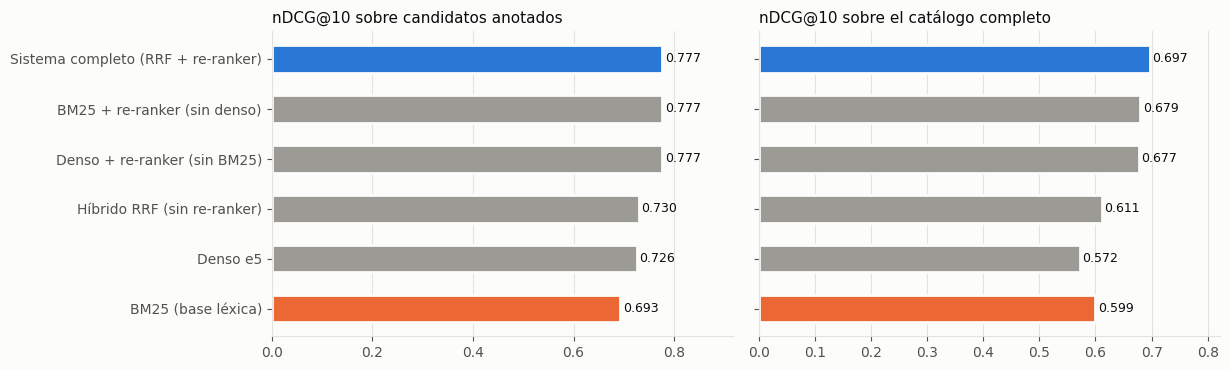

In [ ]:
sys_df, sig_df, per_q = ev.compare_systems(best_cfg, split="test")
display(sys_df.pivot(index="sistema", columns="modo", values="nDCG@10").loc[list(E.SYSTEMS)].round(4))
display(sig_df.round(4))
fig = E.plot_systems(sys_df, C.RESULTS_DIR / "ndcg_sistemas.png")
sys_df.to_csv(C.RESULTS_DIR / "recuperacion_test.csv", index=False)

**Lectura de la tabla**
* *Modelo base*: **BM25 (base léxica)**.
* *Ablación del re-ranker* (componente principal): **Sistema completo** vs **Híbrido RRF (sin re-ranker)**, mismas consultas de test.
* *Ablaciones adicionales de la fusión*: quitar BM25 (**Denso + re-ranker**) o quitar el denso (**BM25 + re-ranker**).
* La columna IC95 es un *bootstrap* pareado por consulta de la diferencia frente a BM25 (si el intervalo no cruza 0 la mejora es robusta).

In [ ]:
lat_ret = {}
for name, (ub, ud, ur) in [("BM25", (True, False, False)), ("Híbrido", (True, True, False)), ("Completo", (True, True, True))]:
    lat_ret[name] = ev.latency_table(replace(best_cfg, use_bm25=ub, use_dense=ud, use_reranker=ur))
    print(name); display(lat_ret[name])
searcher.cfg = best_cfg   # restaurar la configuración del agente

BM25


,total_ms,bm25_s,dense_s,rerank_s
mean,12.0,0.3,0.0,0.0
50%,12.3,0.3,0.0,0.0
max,22.3,1.5,0.1,0.0


Híbrido


,total_ms,bm25_s,dense_s,rerank_s
mean,41.9,0.5,18.5,0.0
50%,42.4,0.4,17.8,0.0
max,76.3,2.8,32.2,0.0


Completo


,total_ms,bm25_s,dense_s,rerank_s
mean,901.9,0.5,18.2,864.0
50%,938.0,0.4,16.4,897.6
max,1131.2,0.9,27.5,1099.4


In [ ]:
# Cinco aciertos y cinco fallos (sistema completo, test, candidatos anotados)
err_df = E.error_analysis(ev, best_cfg, "test", "candidates", n=5)
pd.set_option("display.max_colwidth", 200)
display(err_df)
err_df.to_csv(C.RESULTS_DIR / "aciertos_fallos_recuperacion.csv", index=False)

,tipo,query_id,consulta,nDCG@10,nDCG@10_BM25,top3,n_E,n_cand
0,acierto,108605,view2,1.000,0.249,"[E] Wiko View2 Pro - Smartphone con Pantalla de 6"" (Dual SIM, Oc | [E] WIKO View2 Go – Smartphone con pantalla panorámica de 5,93"" | [E] WIKO View2 Go – Smartphone con pantalla panorámica de 5,93""",4,16
1,acierto,108385,vestidos fiesta,1.000,0.862,"[E] Vectry Rebajas Vestidos De Fiesta Vestidos para Boda Vestido | [E] DIDK Mujer Vestido de Fiesta, Vestido Manga Larga, Vestido A | [E] Overdose Vestido De Fiesta De Noche para Las Mujeres Sexy Si",17,32
2,acierto,108338,vestido calvin klein mujer,1.000,0.680,"[E] Calvin Klein Monogram Stripe Ballet Dress Vestido, Blanco (B | [E] Calvin Klein - Vestido Camisero DE Manga Corta con Logo Grab | [E] Calvin Klein Jeans CK Logo Trim Ls Milano Dress, Vestido par",19,40
3,acierto,107132,urna cenizas pequeñas,1.000,1.000,"[E] Urna pequeña para cenizas humanas personalizadas, 10 ml, imp | [E] zootop Mini urnas de cremación para cenizas, urnas pequeñas | [E] 3 unids pequeñas urnas Cenizas humanas, urnas de Recuerdo pa",28,39
4,acierto,105872,tv 22 pulgadas,1.000,0.851,"[E] Nevir TV 22PULGADAS LED Full HD - NVR - 7705-22FHD2 - N - TD | [E] LG Electronics 22TK410V-PZ - Monitor/TV de 22"" LED con TDT2 | [E] TV LED 22"" INFINITON Full HD (Especial 12V Caravana) Reprodu",6,16
5,fallo,23241,carne,0.028,0.209,"[C] Aobosi Picadora de Carne Eléctrica, 1200W Max, 3 in 1 Salchi | [I] Amix - Monster Beef Protein - Suplemento Alimenticio - Mejor | [C] ORBLUE Ablandador Manual de Carne de Acero Inoxidable",3,16
6,fallo,87168,repuesto vaso licuadora oster,0.145,0.145,"[C] Poweka Piezas de Repuesto Compatible con Licuadora Oster Ost | [C] Oster 004902-050-000 - Base de Batidora de Vaso y Anillo de | [C] Piezas Repuesto de Licuadora, Haofy Cuchilla de Batidoras de",4,16
7,fallo,10743,aspiradoras dyson sin bolsa,0.165,0.165,"[S] Amazon Basics – Potente aspirador de cilindro sin bolsa, par | [S] Hoover Sprint Evo SE61 Aspiradora sin Bolsa de Trineo, Espec | [S] Rowenta Swift Power RO2981 Total Care, aspiradora sin bolsa,",4,40
8,fallo,23318,carpetas sin anillas,0.206,0.385,"[S] Skycase - Carpeta de 6 anillas para archivadores (A5, sin pa | [S] Busquets Carpeta Anillas Recambio Luna LA VOLATIL | [I] Carpeta de Papel Kraft A4 Carpeta Anillas de Papel Kraft Car",16,40
9,fallo,92458,shein ropa niña,0.228,0.096,[S] Sudaderas Mujer Tumblr Cortas con Capucha Chica Adolescente | [S] Mujer Sudaderas con Capucha de Manga Larga para Adolescentes | [I] 4 Piezas de Sujetador de Camisola de Cuello V Bandeau Bralet,1,40


## 4. Tienda simulada

* Precio y stock de cada producto se derivan de `sha256(semilla:product_id)` → **deterministas** e independientes del orden del catálogo (≈8 % agotados, precios log-normales con mediana ≈ 22 €).
* SQLite con restricciones `CHECK (stock >= 0)`, `UNIQUE(quote_id)` en pedidos (idempotencia) e importes en **céntimos enteros**.
* `snapshot("base")` / `restore("base")` fijan el estado inicial de cada escenario.

In [ ]:
from lab4.store import Store
import hashlib
store = Store(C.STORE_DIR / "store.db")
store.reset(catalog.product_id.tolist(), seed=C.SEED)
store.snapshot("base")

def inventory_hash():
    rows = store.con.execute("SELECT product_id, price_cents, stock FROM inventory ORDER BY product_id").fetchall()
    return hashlib.md5(json.dumps([tuple(r) for r in rows]).encode()).hexdigest()

h0 = inventory_hash()
pid = catalog.product_id.iloc[0]
store.set_stock(pid, 999); store.set_price(pid, 1.23)
assert inventory_hash() != h0
store.restore("base")
assert inventory_hash() == h0
store2 = Store(C.STORE_DIR / "store_check.db"); store2.reset(catalog.product_id.tolist(), seed=C.SEED)
rows2 = store2.con.execute("SELECT product_id, price_cents, stock FROM inventory ORDER BY product_id").fetchall()
assert hashlib.md5(json.dumps([tuple(r) for r in rows2]).encode()).hexdigest() == h0
print("✔ La tienda es reproducible (misma semilla ⇒ mismo inventario) y restaurable. Hash:", h0)
inv = pd.read_sql("SELECT * FROM inventory", store.con)
print(inv.describe().round(2))

✔ La tienda es reproducible (misma semilla ⇒ mismo inventario) y restaurable. Hash: bf58c47914a12d422d1d71ffbeee153d
       price_cents     stock  version
count     15000.00  15000.00  15000.0
mean       3088.97     18.42      0.0
std        2881.80     12.07      0.0
min         300.00      0.00      0.0
25%        1399.00      8.00      0.0
50%        2299.00     18.00      0.0
75%        3899.00     29.00      0.0
max       52799.00     39.00      0.0


In [ ]:
# Prueba unitaria de atomicidad e idempotencia (sin LLM)
from lab4.store import StoreError
store.restore("base")
in_stock = inv[inv.stock >= 5].product_id.tolist()[:2]
store.set_stock(in_stock[0], 5); store.set_stock(in_stock[1], 5)
store.set_cart_qty("test", in_stock[0], 2); store.set_cart_qty("test", in_stock[1], 3)
q = store.create_quote("test")
store.set_stock(in_stock[1], 1)                       # otro cliente compra antes de confirmar
try:
    store.confirm_order("test", q["quote_id"])
except StoreError as e:
    print("Rechazado como se esperaba:", e.code, e.data)
assert store.get(in_stock[0])["stock"] == 5, "no debe haber cambios parciales"
assert store.orders("test") == []
store.set_stock(in_stock[1], 5)
q = store.create_quote("test")
r1 = store.confirm_order("test", q["quote_id"]); r2 = store.confirm_order("test", q["quote_id"])
assert r2["duplicate"] and r1["order_id"] == r2["order_id"] and len(store.orders("test")) == 1
assert store.get(in_stock[0])["stock"] == 3 and store.get(in_stock[1])["stock"] == 2
print("✔ Sin cambios parciales; confirmación repetida no duplica:", r1["order_id"], store.integrity_report())
store.restore("base")

Rechazado como se esperaba: stock_insuficiente {'stock_problems': [{'product_id': '0199536015', 'pedido': 3, 'disponible': 1}]}
✔ Sin cambios parciales; confirmación repetida no duplica: P-FB7D1B60 {'negative_stock': 0, 'duplicate_orders': 0, 'orders_without_items': 0}


## 5. LLM y agente

**Control del agente** (implementado por el grupo, `lab4/agent.py`, `lab4/tools.py`):
1. *Reglas deterministas* sobre el mensaje: confirmación explícita (`sí, confirmo…` sin negaciones) y presupuesto (`máximo 30 euros`).
2. *Bucle ReAct* (≤ 6 pasos/turno): el LLM elige herramientas con el formato nativo `<tool_call>` de Qwen; el código las **valida y ejecuta**.
3. *Memoria estructurada* (`ConversationState`): presupuesto, preferencias, últimos resultados numerados, productos mostrados, cotización pendiente, pedidos. Se inyecta como JSON en cada paso → no depende de que el historial textual quepa en contexto.
4. *Guardas en código*: no se añade un producto que no se haya mostrado (anti-alucinación de ids), cantidad entera 1-20, stock disponible, aviso de presupuesto, `confirmar_pedido` solo si (a) hay cotización vigente, (b) se mostró en un turno **anterior**, (c) el usuario confirmó **en este turno**; cualquier cambio del carrito invalida la cotización.
5. *Post-validación*: si la respuesta afirma un pedido que no existe, se reemplaza; el número de pedido real siempre se añade.

**Herramientas**: `buscar_productos`, `detalle_producto`, `verificar_atributo`, `comparar_productos`, `consultar_precio_stock`, `buscar_alternativa`, `registrar_restricciones`, `actualizar_carrito`, `ver_carrito`, `vaciar_carrito`, `cotizar`, `confirmar_pedido`.

In [ ]:
from lab4.llm import LocalLLM
from lab4.agent import ShoppingAgent
try:
    llm = reg.load("llm", lambda: LocalLLM(C.MODELS.llm))
except Exception as e:                      # p. ej. versión de transformers sin soporte de Qwen3
    print("Fallo cargando", C.MODELS.llm, "→", e, "\nSe usa", C.MODELS.llm_fallback)
    llm = reg.load("llm", lambda: LocalLLM(C.MODELS.llm_fallback))
print(gpu_mem())

config.json:   0%|          | 0.00/728 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/9.73k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

... (3 outputs left out)

Fetching 5 files:   0%|          | 0/5 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/399 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

✔ llm: 987.9 s, +6.09 GB VRAM
{'allocated_gb': 7.8, 'reserved_gb': 7.91, 'max_allocated_gb': 7.88, 'total_gb': 15.64}


In [ ]:
# Prueba rápida con traza de herramientas
store.restore("base")
agent = ShoppingAgent(llm, store, searcher, catalog, session_id="demo", trace=True)
for u in ["Hola, busco una mochila para portátil, como mucho 40 euros.",
          "¿La primera es impermeable?"]:
    r = agent.handle(u)
    print("👤", u, "\n🤖", r["response"], "\n", r["timing"], "\n")
    # Control de cordura: en fp16 (la T4 no tiene bf16 nativo) algunos LLM pueden desbordarse y
    # generar basura; si ocurre, cargue C.MODELS.llm_fallback.
    assert r["response"].strip() and "!!!!" not in r["response"], "Salida degenerada del LLM"
print(agent.state.to_prompt(agent.tools._cart_view()[0]))

  ↳ buscar_productos({"consulta": "mochila para portátil", "precio_max": 40.0, "solo_disponibles": true, "k": 3}) -> {"ok": true, "consulta": "mochila para portátil", "resultados": [{"n": 1, "id": "B08865Q9N5", "titulo": "KROSER Mochila para portátil 15.6 Pulgadas Mochila Escolar Mochila para Computadora Universitaria con Puerto de Carga US", "marca": "KROSER", "color": "Gris-15.6''", "precio_eur": 14.99, "stock":
👤 Hola, busco una mochila para portátil, como mucho 40 euros. 
🤖 Tengo 3 mochilas para portátil disponibles bajo 40 euros:

1. **KROSER** - 14,99 euros, gris, 15,6 pulgadas, stock: 39  
2. **JDC** - 38,99 euros, negro/gris, para moto, stock: 26  
3. **Della Gao** - 10,99 euros, negro, 17,3 pulgadas, stock: 3  

¿Te quedas con alguna? 
 {'llm_s': 19.453929157000402, 'tools_s': 1.8336894289996053, 'llm_calls': 2, 'agent_total_s': 21.344587779999983} 

  ↳ verificar_atributo({"producto": "B08865Q9N5", "atributo": "impermeable"}) -> {"ok": true, "atributo": "impermeable", "estado

## 6. Escenarios operativos (22, texto)

Cada escenario parte de `restore("base")`, aplica su `setup` determinista (precio/stock por tipo de producto), ejecuta los turnos del usuario y aplica eventos externos (`hooks`) cuando corresponde (p. ej. *otro cliente compra stock entre la cotización y la confirmación*). Se verifica automáticamente el estado final de la tienda, las operaciones y las respuestas, y se cuentan **incumplimientos de restricciones**: presupuesto superado, pedido sin confirmación explícita, pedido duplicado, stock negativo y pedido de un producto agotado.

In [ ]:
from lab4.scenarios import SCENARIOS, run_scenario
SCN = {s.id: s for s in SCENARIOS}
pd.DataFrame([{"id": s.id, "escenario": s.title, "categoría": s.category, "turnos": len(s.turns),
               "voz": "🎙️" if s.voice else ""} for s in SCENARIOS])

,id,escenario,categoría,turnos,voz
0,S01,Compra que cumple restricciones,compra,3,🎙️
1,S02,Solicitud ambigua que requiere aclaración,aclaracion,3,🎙️
2,S03,Cambio de cantidad conservando el presupuesto,cambio,3,🎙️
3,S04,Producto agotado con alternativa,agotado,4,🎙️
4,S05,Producto agotado sin solución,agotado,2,
5,S06,Corrección de una transcripción antes de comprar,correccion,3,🎙️
6,S07,Cambio de stock entre cotización y confirmación + confirmación repetida,stock,5,🎙️
7,S08,Presupuesto excedido y ajuste,presupuesto,3,
8,S09,Dos productos con presupuesto,compra,3,
9,S10,Comparación de alternativas sin compra,comparacion,3,


In [ ]:
text_results = []
for s in SCENARIOS:
    print(f"━━━━━━━━ {s.id} · {s.title} ━━━━━━━━")
    text_results.append(run_scenario(s, llm, store, searcher, catalog))
json.dump(text_results, open(C.RESULTS_DIR / "escenarios_texto.json", "w"), ensure_ascii=False, indent=1, default=str)
scn_df, scn_summary = E.scenario_table(text_results)
display(scn_df); print(json.dumps(scn_summary, indent=2, ensure_ascii=False))

━━━━━━━━ S01 · Compra que cumple restricciones ━━━━━━━━
👤 Hola, quiero comprar dos botellas de agua reutilizables y tengo un presupuesto de cuarenta euros.
🤖 Tienes tres opciones de botellas de agua reutilizable disponibles dentro de tu presupuesto de 40 euros. ¿Te gustaría elegir las primeras dos que encuentro?
   ops: ['buscar_productos']
👤 Me quedo con la primera opción, prepárame la cotización.
🤖 Te resumo la cotización: 2 × HoneyHolly Botella de Agua Acero Inoxidable a 8,99 euros; envío 4,99 euros. Total: 22,97 euros, dentro de tu presupuesto de 40 euros. ¿Confirmas el pedido?
   ops: ['actualizar_carrito', 'cotizar']
👤 Sí, confirmo el pedido.
🤖 Tu pedido ha sido confirmado con éxito. El número de pedido es P-A5F8354D. El total es 22,97 euros, que incluye 2 × HoneyHolly Botella de Agua Acero Inoxidable. ¡Gracias por tu compra!
   ops: ['confirmar_pedido']
✅ OK

━━━━━━━━ S02 · Solicitud ambigua que requiere aclaración ━━━━━━━━
👤 Necesito un cargador.
🤖 ¿Qué tipo de cargador necesit

,id,escenario,categoría,ok,turnos,operaciones,fallos,incumplimientos
0,S01,Compra que cumple restricciones,compra,✅,3,4,,
1,S02,Solicitud ambigua que requiere aclaración,aclaracion,✅,3,5,,
2,S03,Cambio de cantidad conservando el presupuesto,cambio,✅,3,8,,
3,S04,Producto agotado con alternativa,agotado,✅,4,8,,
4,S05,Producto agotado sin solución,agotado,✅,2,1,,
5,S06,Corrección de una transcripción antes de comprar,correccion,✅,3,6,,
6,S07,Cambio de stock entre cotización y confirmación + confirmación repetida,stock,✅,5,7,,
7,S08,Presupuesto excedido y ajuste,presupuesto,❌,3,8,se esperaban 1 pedidos y hay 0; 'mochila': cantidad 0 != 1,
8,S09,Dos productos con presupuesto,compra,✅,3,7,,
9,S10,Comparación de alternativas sin compra,comparacion,✅,3,4,,


{
  "escenarios": 22,
  "completados_ok": 19,
  "porcentaje_ok": 86.4,
  "incumplimientos_totales": 0,
  "incumplimientos_por_tipo": {}
}


### Ablación a nivel de sistema (mismos escenarios)
Se repiten los escenarios **desactivando las reglas deterministas** (`use_rules=False`: memoria de presupuesto y color por reglas, detección de confirmación explícita, cotización y confirmación automáticas, resumen de importes generado por código y autocorrección de acciones no ejecutadas; el LLM decide solo) para medir cuánto aportan al porcentaje de éxito y a los incumplimientos. Así la ablación se hace "utilizando los mismos escenarios", como pide el enunciado, además de la ablación del re-ranker en recuperación.

In [ ]:
# use_rules=False: sin reglas de memoria (presupuesto/color), sin detección de confirmación explícita
# (el LLM decide cuándo confirmar), sin cotización/confirmación automáticas ni resumen generado por código.
abl_cfg = replace(C.AGENT, use_rules=False)
abl_results = [run_scenario(s, llm, store, searcher, catalog, verbose=False, agent_cfg=abl_cfg) for s in SCENARIOS]
abl_df, abl_summary = E.scenario_table(abl_results)
cmp = pd.DataFrame([{"variante": "Sistema completo", **scn_summary}, {"variante": "Sin guardas deterministas", **abl_summary}])
display(cmp[["variante", "escenarios", "completados_ok", "porcentaje_ok", "incumplimientos_totales", "incumplimientos_por_tipo"]])
json.dump(abl_results, open(C.RESULTS_DIR / "escenarios_ablacion.json", "w"), ensure_ascii=False, indent=1, default=str)

,variante,escenarios,completados_ok,porcentaje_ok,incumplimientos_totales,incumplimientos_por_tipo
0,Sistema completo,22,19,86.4,0,{}
1,Sin guardas deterministas,22,10,45.5,0,{}


## 7. Voz: grabación de referencia, ASR y TTS con clonación

**Voz propia o autorizada**: un integrante del grupo graba ~20-30 s leyendo el texto de referencia (o sube un `.wav`). Las respuestas sintetizadas son textos **distintos** de la referencia (se comprueba con el solapamiento de trigramas).

> Si el micrófono del navegador no funciona, suba el audio a `work/audios/` con los nombres indicados y omita la celda de grabación.

In [ ]:
from lab4.speech import record, ASR, VoiceTTS, SpeakerSimilarity, load_audio, text_overlap, to_wav16k
from IPython.display import Audio, display

REFERENCE_TEXT = ("Hola, soy integrante del grupo del laboratorio cuatro de aprendizaje profundo. "
                  "Esta grabación se usa únicamente como referencia para clonar mi voz con fines académicos. "
                  "Leo este párrafo con calma, en un lugar silencioso, para que el modelo capture bien "
                  "el timbre, el ritmo y la entonación de mi forma de hablar.")
REF_WAV = C.AUDIO_DIR / "referencia.wav"
print(REFERENCE_TEXT)

Hola, soy integrante del grupo del laboratorio cuatro de aprendizaje profundo. Esta grabación se usa únicamente como referencia para clonar mi voz con fines académicos. Leo este párrafo con calma, en un lugar silencioso, para que el modelo capture bien el timbre, el ritmo y la entonación de mi forma de hablar.


In [ ]:
# Ejecutar solo si aún no existe la grabación de referencia
if not REF_WAV.exists():
    REF_WAV, _ = record(REF_WAV, max_seconds=40, label="lea el texto de referencia")
display(Audio(str(REF_WAV)))
print(f"Duración: {len(load_audio(REF_WAV))/16000:.1f} s")

Duración: 23.5 s


In [ ]:
asr = reg.load("asr", lambda: ASR())
tts = reg.load("tts", lambda: VoiceTTS(REF_WAV))
spk = reg.load("speaker_verif", lambda: SpeakerSimilarity())
pd.DataFrame(reg.load_report)

In [ ]:
txt, dt = asr.transcribe(REF_WAV)
print(f"ASR de la referencia ({dt:.2f} s):", txt)
demo_text = "Te he preparado la cotización: dos botellas por diecisiete con noventa y ocho euros. ¿Confirmas el pedido?"
assert text_overlap(demo_text, REFERENCE_TEXT) < 0.1
wav, dt = tts.synthesize(demo_text, C.AUDIO_DIR / "demo_tts.wav")
print(f"TTS: {dt:.2f} s para {len(wav)/tts.SR:.1f} s de audio (RTF {dt/(len(wav)/tts.SR):.2f})")
display(Audio(str(C.AUDIO_DIR / "demo_tts.wav")))

## 8. Escenarios por voz

Seis escenarios cubren las situaciones pedidas (S03, S01, S02 y S07 tienen varias intervenciones del usuario):

| Situación del enunciado | Escenario |
|---|---|
| Compra que cumple restricciones y termina en pedido | **S01** |
| Solicitud ambigua que requiere aclaración | **S02** |
| Cambio de cantidad o preferencia conservando restricciones | **S03** |
| Producto agotado → alternativa | **S04** |
| Corrección de una transcripción antes de comprar | **S06** |
| Cambio de stock entre cotización y confirmación + confirmación repetida | **S07** |

**Paso 1 — audios de usuario.** Con `USAR_TURNOS_SINTETICOS = True` (valor por defecto) los 20 turnos se generan aquí mismo, en Colab, con una voz de stock de XTTS (*Claribel Dervla*) distinta de la voz clonada; con `False`, cada intervención se graba por micrófono leyendo el texto mostrado. En ambos casos se guardan en Drive (`audios/S0x_t{i}.wav`) y no se regeneran si ya existen. Los turnos sintéticos son el mejor caso para el ASR (audio limpio): se declara como limitación.

**Paso 2 — ejecutar** cada escenario con el audio (ASR) y **repetirlo con la transcripción correcta** como entrada, para separar los errores del ASR de los del agente.

*Corrección de transcripción (S06)*: antes de ejecutar, la transcripción se muestra y el usuario puede corregirla. Como no se puede forzar un error real del ASR de forma reproducible, el escenario **inyecta un error documentado** ("tres" → "13") y el usuario simulado lo corrige comparando con lo que dijo (revisión de cantidades/importes/productos). Además, el agente siempre lee cantidades y total antes de confirmar, lo que permite corregir por voz.

In [ ]:
# True: genera en Colab los turnos de usuario con una voz de stock de XTTS (reproducible, sin micrófono).
# False: graba cada turno por micrófono. Los audios que ya existan en Drive no se regeneran.
USAR_TURNOS_SINTETICOS = True
VOZ_USUARIO_SINTETICA = "Claribel Dervla"   # voz de stock de XTTS, distinta de la voz clonada

VOICE = [s for s in SCENARIOS if s.voice]
def voice_turns(s): return s.voice_turns or s.turns
def turn_wav(s, i): return C.AUDIO_DIR / f"{s.id}_t{i+1}.wav"

for s in VOICE:
    for i, t in enumerate(voice_turns(s)):
        if turn_wav(s, i).exists():
            continue
        if USAR_TURNOS_SINTETICOS:
            # Reutiliza el XTTS ya cargado (tts.api): no se carga un segundo modelo en la GPU.
            tts.api.tts_to_file(text=t, speaker=VOZ_USUARIO_SINTETICA, language="es", file_path=str(turn_wav(s, i)))
            print(f"🗣️ {s.id} · turno {i+1} generado: «{t}»")
        else:
            print(f"\n{s.id} · turno {i+1}: lea en voz alta →  «{t}»")
            record(turn_wav(s, i), max_seconds=20, label=f"{s.id} turno {i+1}")
origen = "sintéticos (XTTS, generados en Colab)" if USAR_TURNOS_SINTETICOS else "grabados por micrófono"
print("Audios disponibles:", sorted(p.name for p in C.AUDIO_DIR.glob("S0*_t*.wav")), "| turnos nuevos:", origen)

🗣️ S01 · turno 1 generado: «Hola, quiero comprar dos botellas de agua reutilizables y tengo un presupuesto de cuarenta euros.»
🗣️ S01 · turno 2 generado: «Me quedo con la primera opción, prepárame la cotización.»
🗣️ S01 · turno 3 generado: «Sí, confirmo el pedido.»
🗣️ S02 · turno 1 generado: «Necesito un cargador.»
🗣️ S02 · turno 2 generado: «Es para un móvil con USB C, quiero solo uno. Me vale el primero que me muestres, prepara la cotización.»
🗣️ S02 · turno 3 generado: «Sí, confirmo.»
🗣️ S03 · turno 1 generado: «Quiero tres cuadernos y dos bolígrafos, con un máximo de treinta euros. Elige los primeros que encuentres.»
🗣️ S03 · turno 2 generado: «Mejor que sean cinco cuadernos en lugar de tres. Prepara la cotización.»
🗣️ S03 · turno 3 generado: «Sí, confirmo.»
🗣️ S04 · turno 1 generado: «Quiero dos tazas de café, la primera que encuentres está bien.»
🗣️ S04 · turno 2 generado: «Prepárame la cotización.»
🗣️ S04 · turno 3 generado: «Vale, cámbiala por la alternativa que me propones y v

In [ ]:
import re
from lab4.pipeline import VoiceAssistant
from lab4.metrics import entity_errors

def make_voice_turn_fn(s, review=False):
    def fn(agent, i, gold_text):
        va = VoiceAssistant(asr, agent, tts)
        wav = turn_wav(s, i)
        t_end = time.perf_counter()   # audio pregrabado: el reloj empieza al terminar la carga del audio
        perturb = s.asr_perturb.get(i)
        correction, asr_result = None, None
        if review:
            # Revisión previa a la ejecución: se transcribe, se muestra y el usuario corrige si
            # cantidades, importes o productos no coinciden con lo que dijo.
            raw, asr_s = asr.transcribe(wav)
            asr_result = (raw, asr_s)
            hyp = re.sub(perturb[0], perturb[1], raw, flags=re.I) if perturb else raw
            e = entity_errors(gold_text, hyp, s.product_terms if i == 0 else ())
            print(f"   📝 Transcripción mostrada al usuario: «{hyp}»")
            if e["qty_err"] or e["amount_err"] or e["product_err"]:
                print(f"   ✏️ Corregida por el usuario antes de ejecutar → «{gold_text}»")
                correction = gold_text
        r = va.turn(wav, t_end=t_end, correction=correction, perturb=perturb, tag=f"{s.id}_t{i+1}",
                    asr_result=asr_result)
        r["gold"] = gold_text
        return r
    return fn

voice_results, gold_results = [], []
for s in VOICE:
    print(f"━━━━━━━━ VOZ {s.id} · {s.title} ━━━━━━━━")
    voice_results.append(run_scenario(s, llm, store, searcher, catalog, turns=voice_turns(s),
                                      turn_fn=make_voice_turn_fn(s, review=(s.id == "S06"))))
    print(f"━━━━━━━━ TRANSCRIPCIÓN CORRECTA {s.id} ━━━━━━━━")
    gold_results.append(run_scenario(s, llm, store, searcher, catalog, turns=voice_turns(s), verbose=False))
json.dump(voice_results, open(C.RESULTS_DIR / "escenarios_voz.json", "w"), ensure_ascii=False, indent=1, default=str)
json.dump(gold_results, open(C.RESULTS_DIR / "escenarios_voz_gold.json", "w"), ensure_ascii=False, indent=1, default=str)

In [ ]:
vcmp = pd.DataFrame([{"escenario": v["id"], "título": v["title"], "con ASR": "✅" if v["passed"] else "❌",
                      "con transcripción correcta": "✅" if g["passed"] else "❌",
                      "fallos ASR": "; ".join(v["failures"] + v["violations"]),
                      "pedidos finales": len(v["final_state"]["orders"])}
                     for v, g in zip(voice_results, gold_results)])
display(vcmp)
asr_df, asr_tot = E.asr_error_table(voice_results, SCN)
display(asr_df[["escenario", "turno", "referencia", "asr", "WER", "qty_err", "amount_err", "product_err", "corregido"]])
print(json.dumps(asr_tot, indent=2, ensure_ascii=False, default=float))

In [ ]:
# Registro completo de un escenario por voz: audios, transcripciones, operaciones y estado final
v = voice_results[-1]
for t in v["turns"]:
    print(f"🎙️ {Path(t['audio_in']).name} | ASR: «{t['asr_raw']}» | ejecutado: «{t['executed_text']}»")
    print("   ops:", [(s['tool'], s['result'].get('error') or 'ok') for s in t["steps"]])
    print("   🤖", t["response"]); display(Audio(t["audio_out"]))
print(json.dumps(v["final_state"], indent=1, ensure_ascii=False, default=str)[:2000])

## 9. Calidad de la voz sintetizada
* **Inteligibilidad**: WER entre el texto que se quería sintetizar y la transcripción de Whisper del audio sintetizado.
* **Semejanza con la voz de referencia**: coseno entre x-vectors WavLM. Se dan dos cotas: la referencia partida en dos mitades (misma persona, cota superior) y una voz distinta (voz de stock de XTTS, cota inferior).
* Se verifica que ningún texto sintetizado reutiliza el texto de la referencia (solapamiento de trigramas ≈ 0).

In [ ]:
other = C.AUDIO_DIR / "otra_voz.wav"
if not other.exists():
    tts.api.tts_to_file(text="Buenos días, esta es una voz diferente usada como control.", speaker="Ana Florence",
                        language="es", file_path=str(other))
tts_df, tts_bounds = E.tts_quality(asr, spk, tts, REF_WAV, REFERENCE_TEXT, voice_results, other_voice_wav=other)
display(tts_df.describe().round(3)); print(tts_bounds)
tts_df.to_csv(C.RESULTS_DIR / "calidad_tts.csv", index=False)

/usr/local/lib/python3.13/dist-packages/torch/nn/functional.py:6829: UserWarning: Support for mismatched key_padding_mask and attn_mask is deprecated. Use same type for both instead.
  key_padding_mask = _canonical_mask(
[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignore_warning=True). To use Whisper for long-form transcription, use rather the model's `generate` method directly as the model relies on its own chunking mechanism (cf. Whisper original paper, section 3.8. Long-form Transcription).
[transformers] Using `chunk_length_s` is very experimental with seq2seq models. The results will not necessarily be entirely accurate and will have caveats. More information: https://github.com/huggingface/transformers/pull/20104. Ignore this warning with pipeline(..., ignor

,turno,WER_inteligibilidad,similitud_referencia,solapamiento_trigramas_ref
count,20.000,20.000,20.000,20.0
mean,2.300,0.253,0.952,0.0
std,1.174,0.156,0.010,0.0
min,1.000,0.000,0.932,0.0
25%,1.000,0.123,0.945,0.0
50%,2.000,0.303,0.954,0.0
75%,3.000,0.374,0.960,0.0
max,5.000,0.483,0.968,0.0


{'ref_mitad_vs_mitad (cota sup.)': 0.9856849908828735, 'otra_voz_vs_ref (cota inf.)': 0.6633564829826355}


## 10. Latencia
Tiempo **desde que termina la grabación hasta que la respuesta puede reproducirse**, desglosado en ASR, LLM, herramientas (RAG + tienda) y TTS. La **carga inicial** de modelos se reporta aparte (tabla del registro de modelos); el primer turno incluye además el calentamiento de CUDA.

In [ ]:
lat_df = E.latency_breakdown(voice_results)
display(lat_df.describe().loc[["mean", "50%", "max"]].round(2))
print("Primer turno (calentamiento) vs resto:",
      round(lat_df.total_s.iloc[0], 2), "s vs", round(lat_df.total_s.iloc[1:].mean(), 2), "s")
E.plot_latency(lat_df, C.RESULTS_DIR / "latencia.png")
load_df = pd.DataFrame(reg.load_report); display(load_df)
print("Memoria GPU:", gpu_mem())

## 11. Análisis de aciertos, fallos y limitaciones

Las celdas siguientes listan automáticamente los aciertos y fallos (recuperación y escenarios). El análisis cualitativo de causas se completa en `README.md` (sección *Análisis de errores*) con los casos concretos de esta ejecución.

In [ ]:
print("=== Escenarios con fallo (texto) ===")
for r in text_results:
    if not r["passed"]:
        print(f"- {r['id']} {r['title']}: {r['failures'] + r['violations']}")
        for t in r["turns"]:
            print(f"    👤 {t['user']}\n    🤖 {t['response'][:200]}\n    ops: {[(s['tool'], s['result'].get('error') or 'ok') for s in t['steps']]}")
print("\n=== Escenarios correctos ===", [r["id"] for r in text_results if r["passed"]])

In [ ]:
sections = [
    ("Versiones y modelos", versions),
    ("Datos", json.loads((C.DATA_DIR / "summary.json").read_text())),
    ("Ajuste en desarrollo (fusión)", grid_dev), ("Ajuste en desarrollo (profundidad del re-ranker)", depth_dev),
    ("Recuperación en test (nDCG@10)", sys_df), ("Significancia frente a BM25", sig_df),
    ("Aciertos y fallos de recuperación", err_df),
    ("Escenarios de texto", scn_df), ("Resumen escenarios", scn_summary),
    ("Ablación de guardas deterministas", cmp[["variante", "porcentaje_ok", "incumplimientos_totales"]]),
    ("Escenarios por voz vs transcripción correcta", vcmp),
    ("Errores de ASR", asr_df.drop(columns=["referencia"])), ("Totales ASR", asr_tot),
    ("Calidad TTS", tts_df.describe().reset_index()), ("Cotas de semejanza", tts_bounds),
    ("Latencia por etapa (s)", lat_df.describe().reset_index()), ("Carga de modelos", load_df),
]
print(E.write_report(SOL_DIR / "RESULTADOS.md", sections))

## 12. Demostración en vivo (para el video)
Conversación por turnos con el micrófono: se graba, se muestra la transcripción (puede corregirse escribiendo antes de pulsar Enter), se ejecuta el agente y se reproduce la respuesta con la voz clonada. Se imprime la espera real de cada etapa. Escriba `fin` para terminar.

In [ ]:
store.restore("base")
live_agent = ShoppingAgent(llm, store, searcher, catalog, session_id="live", trace=True)
va = VoiceAssistant(asr, live_agent, tts)
for k in range(1, 20):
    wav, t_end = record(C.AUDIO_DIR / f"live_t{k}.wav", max_seconds=25, label=f"turno {k}")
    hyp, asr_s = asr.transcribe(wav)
    print(f"📝 Transcripción ({asr_s:.2f} s):", hyp)
    fix = input("Enter para aceptar, texto para corregir, 'fin' para terminar: ").strip()
    if fix.lower() == "fin":
        break
    # La espera de revisión humana se excluye; la latencia = ASR + agente + TTS
    r = va.turn(wav, correction=fix or None, tag=f"live_t{k}", play=True, asr_result=(hyp, asr_s))
    print("🤖", r["response"])
    print("⏱️", {k2: round(v2, 2) for k2, v2 in r["latency"].items()})
print(live_agent.state.to_prompt(live_agent.tools._cart_view()[0]))
print(store.orders("live"))

<IPython.core.display.Javascript object>

MessageError: NotAllowedError: Permission denied